# Datos de primeras llegadas: inversión de rayos rectos con cotas

**Pregunta:** Para una geometría fija de primeras llegadas, ¿cómo cambian el modelo recuperado los pesos de incertidumbre, la suavidad y las cotas de velocidad?

**Nivel 3 — Comparación con métodos publicados** · 55 min · prerrequisitos: tomografía de tiempos de viaje, problemas inversos lineales y mínimos cuadrados ponderados.

## Objetivos

Traducir longitudes de rayo y tiempos picados a un problema de lentitud dimensionalmente consistente; explicar por qué las cotas de velocidad deben incluirse en la optimización; distinguir ajuste de datos, cobertura geométrica y error respecto de la verdad; y comparar estimaciones acotadas con métodos publicados de mínimos cuadrados de SciPy sobre las mismas observaciones. Cada inversión llama la tubería del repositorio. Este notebook enseña el contrato de datos y el cálculo; no reproduce el solver mediante código propio.

## Preparación

El entorno fijado tiene los paquetes siguientes. En un entorno limpio use este comando familiar; el método se importa desde la tubería del producto.

~~~bash
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8
~~~

El ejecutor de notebooks imprime las versiones activas antes de calcular.

In [1]:
# Importe las bibliotecas fijadas y la tubería real del producto.
from importlib.metadata import version
from pathlib import Path
import json
import sys
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import lsq_linear
from scipy.sparse.linalg import lsqr
root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
import velocity_user_data as user_velocity
from velocity_validation import (
    _difference_gram, acquisition, background, cell_length_matrix,
)
print({name: version(name) for name in ("numpy", "scipy", "matplotlib")})

{'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8'}


## Datos

Este control reproducible usa la adquisición A creada en el repositorio, no observaciones de campo descargadas. Contiene 128 segmentos rectos fijos sobre una grilla de 16 por 16 celdas que abarca 800 m horizontalmente y 800 m de profundidad. La velocidad de referencia aumenta con la profundidad. El operador de intersección por celda del producto calcula los tiempos limpios; una semilla fija agrega después ruido gaussiano independiente con desviación estándar declarada de 1 ms a cada pick. Esto prueba un cálculo numérico definido. No demuestra que la geometría, los picks o las incertidumbres describan un levantamiento real.

La inversión recibe extremos de rayos, tiempos con ruido, desviaciones estándar, unidades físicas, marco de coordenadas, declaración de derechos y un peso explícito de regularización. La verdad sintética queda fuera de la solicitud y se usa después de resolver para calcular un error de control. Un levantamiento de usuario sin etiquetas no tiene verdad conocida, por lo que su flujo no recibe una puntuación de error respecto de verdad.

El ejemplo de Königsee de pyGIMLi, enlazado al proveedor, es un flujo separado de refracción de campo con otra geometría de sensores y tratamiento no lineal de rayos. Se cita solo como contexto. Esta calculadora local de rayos fijos no reemplaza ese solver, no reproduce esos picks ni establece elegibilidad de campo.

El constructor de adquisición, el modelo de referencia y la rutina de intersección por celda generan la entrada controlada. Se usa la misma geometría para los tiempos directos y la inversión; por ello, el control aísla la inversa declarada sin afirmar física de rayos independiente.

In [2]:
# Genere rayos creados, modelo de referencia y picks sintéticos con semilla.
rays = acquisition("A")
truth = background()
ray_lengths = cell_length_matrix(rays)
random = np.random.default_rng(20261027)
sigma = np.full(len(rays), 0.001)
clean_times = ray_lengths @ (1.0 / truth.ravel())
observed = clean_times + random.normal(0.0, sigma)
offsets = np.hypot(rays[:, 2] - rays[:, 0], rays[:, 3] - rays[:, 1])
print("rayos:", len(rays), "grilla:", truth.shape,
      "rango de tiempo [s]:", (float(observed.min()), float(observed.max())))
print("sigma declarado [ms]:", float(1000 * sigma[0]))

rayos: 128 grilla: (16, 16) rango de tiempo [s]: (0.35859294707828415, 0.4848768263162341)
sigma declarado [ms]: 1.0


### Geometría de rayos y tiempos picados

La figura muestra toda la adquisición sintética y la relación entre distancia y tiempo observado.

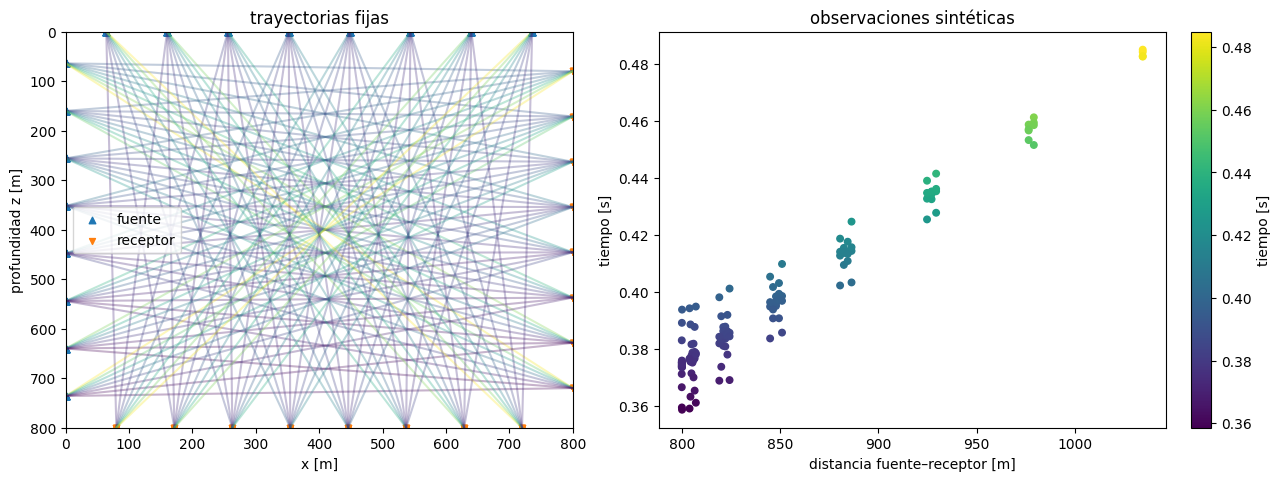

In [3]:
# Dibuje las trayectorias fijas y compare esos tiempos con la distancia.
fig, axes = plt.subplots(1, 2, figsize=(12.7, 4.7), constrained_layout=True)
span = max(float(observed.max() - observed.min()), 1e-12)
for ray, time_s in zip(rays, observed):
    shade = (time_s - observed.min()) / span
    axes[0].plot([ray[0], ray[2]], [ray[1], ray[3]],
                 color=plt.cm.viridis(shade), alpha=0.3)
axes[0].scatter(rays[:, 0], rays[:, 1], marker="^", s=22, label="fuente")
axes[0].scatter(rays[:, 2], rays[:, 3], marker="v", s=18, label="receptor")
axes[0].set(xlim=(0, 800), ylim=(800, 0), xlabel="x [m]",
            ylabel="profundidad z [m]", title="trayectorias fijas")
axes[0].legend()
points = axes[1].scatter(offsets, observed, c=observed, cmap="viridis", s=22)
axes[1].set(xlabel="distancia fuente–receptor [m]", ylabel="tiempo [s]",
            title="observaciones sintéticas")
fig.colorbar(points, ax=axes[1], label="tiempo [s]")
plt.show()

El panel izquierdo dibuja cada segmento fijo entre fuente y receptor e identifica ambos extremos. El panel derecho muestra los mismos tiempos con ruido frente a la distancia. La densidad de trayectorias varía espacialmente, pero la figura por sí sola no identifica qué contrastes de velocidad pueden recuperarse. El color codifica tiempo observado, no profundidad ni velocidad estimada.

## Método

Una trayectoria recta fija convierte la relación de tiempo de viaje en un sistema lineal. Para el rayo i y la celda j, Aᵢⱼ es la longitud en metros del trayecto dentro de esa celda. La lentitud sⱼ=1/vⱼ tiene unidades s/m, de modo que el tiempo discreto tᵢ=Σⱼ Aᵢⱼsⱼ tiene unidades de segundos. El producto ensambla A a partir de segmentos y sus intersecciones con las celdas. Como las trayectorias se fijan antes de invertir, cambiar la velocidad no curva un rayo.

El parámetro del solver es una perturbación respecto de una referencia declarada. Defina q=1000(s−s₀), medido en 10⁻³ s/m, donde s₀=1/v₀. Cada residual se divide por la desviación estándar suministrada σᵢ. El sistema escalado de datos es

$$
B = \operatorname{diag}(1/\sigma)A/1000,\qquad
y = \operatorname{diag}(1/\sigma)(t-As_0).
$$

El producto minimiza ajuste ponderado más penalizaciones de diferencias espaciales y de ridge:

$$
\min_q\; \|Bq-y\|_2^2 + \lambda\|Dq\|_2^2 + 0.01\|q\|_2^2 .
$$

D es el operador de diferencias entre celdas vecinas horizontales y verticales del producto. La penalización de diferencias evita cambios abruptos entre celdas; el término ridge pequeño hace definida positiva la Hessiana. Lambda es un campo explícito de la solicitud. Su efecto depende de la incertidumbre, el modelo de referencia, la escala de q, la grilla y el operador de diferencias. No se selecciona usando una verdad desconocida.

El intervalo físico declarado es de 1400 a 4000 m/s. Como la lentitud es el recíproco de la velocidad, la desigualdad se invierte al expresarla para q:

$$
1000(1/4000-s_0) \le q \le 1000(1/1400-s_0).
$$

El producto resuelve esta cuadrática con caja mediante un método determinista de conjunto activo primal. En cada iteración resuelve sobre la cara libre actual, avanza solo hasta que una cota bloquea la dirección y libera una cota activa únicamente si su multiplicador incumple el signo KKT. El residuo KKT proyectado se recalcula desde el arreglo de velocidad devuelto; su tolerancia relativa es 10⁻⁹. Esto mide optimalidad numérica del objetivo finito declarado. No valida la aproximación de rayos rectos, la calidad de los picks ni la recuperación geológica.

Lea las salidas como evidencias separadas. Los tiempos predichos y los residuales con signo describen el ajuste a las observaciones entregadas. La cobertura suma longitud de trayecto dentro de cada celda e indica dónde esta adquisición aporta soporte geométrico. No es resolución, incertidumbre posterior ni intervalo de confianza. Solo este control sintético creado tiene verdad conocida y su error de velocidad se calcula después de la inversión. La regularización y una geometría limitada permiten que varios modelos ajusten datos similares; un residual pequeño no demuestra un modelo terrestre único.

La entrada es un contrato JSON cerrado: identificadores de rayo únicos, cuatro coordenadas finitas por segmento, marco local-x-z-down declarado, unidades de metros y segundos, tiempos e incertidumbres positivos y finitos, y lambda explícito finito. Las claves desconocidas, los identificadores duplicados y la geometría mal formada se rechazan antes de importar bibliotecas numéricas. El punto de entrada local recibe bytes originales, para que quien llama conserve y calcule el hash exacto antes de interpretar el archivo. Este flujo no carga datos, no consulta proveedores, no instala paquetes implícitamente ni contacta un servidor.

La solicitud se construye campo por campo antes de ejecutar el solver. Así, las unidades y los derechos se pueden inspeccionar en vez de inferir desde los arreglos numéricos. El validador rechaza estructuras mal formadas o ambiguas antes de importar bibliotecas numéricas; conservar los bytes originales también entrega una identidad estable al archivo local.

In [4]:
# Forme la solicitud cerrada y ejecute el validador del producto.
request = {
    "schema": user_velocity.SCHEMA,
    "id": "m12-notebook-control",
    "source": {"citation": "Authored reproducible teaching control",
               "rights": "owner-permitted", "scope": "synthetic-control"},
    "frame": "local-x-z-down",
    "units": {"distance": "m", "time": "s", "velocity": "m/s"},
    "ray_ids": [f"ray-{index:03d}" for index in range(len(rays))],
    "rays_m": rays.tolist(), "times_s": observed.tolist(),
    "sigma_s": sigma.tolist(), "lambda": 100.0,
}
request_bytes = json.dumps(request, allow_nan=False).encode("utf-8")
validated = user_velocity.validate_request(request_bytes)
print("claves validadas:", sorted(validated))
print("bytes de fuente:", len(request_bytes))

claves validadas: ['frame', 'id', 'lambda', 'ray_ids', 'rays_m', 'schema', 'sigma_s', 'source', 'times_s', 'units']
bytes de fuente: 10398


La llamada siguiente ejecuta el método público del producto sobre la solicitud validada. Los arreglos se leen con su orientación declarada: filas de profundidad y columnas de distancia. No se transpone el modelo para reinterpretar sus celdas.

In [5]:
# Ejecute la inversión actual del producto sobre el control creado.
result = user_velocity.calculate(request_bytes)
classical = result["results"]["classical"]
velocity = np.asarray(classical["velocity_m_s"])
coverage = np.asarray(result["coverage_m"])
residual_ms = 1000 * np.asarray(classical["residual_s"])
truth_rmse = float(np.sqrt(np.mean((velocity - truth) ** 2)))
print("motor:", result["engine"], "rayos:", len(rays), "grilla:", velocity.shape)
print("WRMS ponderado de datos:", round(classical["data_wrms"], 6))
print("RMSE de verdad sintética [m/s]:", round(truth_rmse, 3))
print("celdas activas:", classical["active_bound_cells"],
      "KKT proyectado:", f"{classical['kkt_relative']:.3e}")
print("umbral KKT:", classical["kkt_relative_tolerance"],
      "iteraciones:", classical["solver_iterations"])

motor: {'numpy': '2.2.6', 'scipy': '1.15.2', 'user_tool_sha256': '5840ce32207126eae7c90bdb710935ed4930e0610417a5d825d6d5945cf12f9b', 'velocity_operator_sha256': '2b9ed95d3ba7b1b0f9f80167fa610640dc75c8a142dafb9f7f09791b96a1fd44', 'checkpoint_sha256': None, 'checkpoint_protocol': None, 'refinement_code_sha256': None} rayos: 128 grilla: (16, 16)
WRMS ponderado de datos: 0.115434
RMSE de verdad sintética [m/s]: 26.56
celdas activas: 0 KKT proyectado: 1.328e-14
umbral KKT: 1e-09 iteraciones: 1


### Lea modelo ajustado, soporte y residual

Los cuatro paneles mantienen separados los valores del modelo, la geometría, los residuales de datos y el error respecto de verdad sintética.

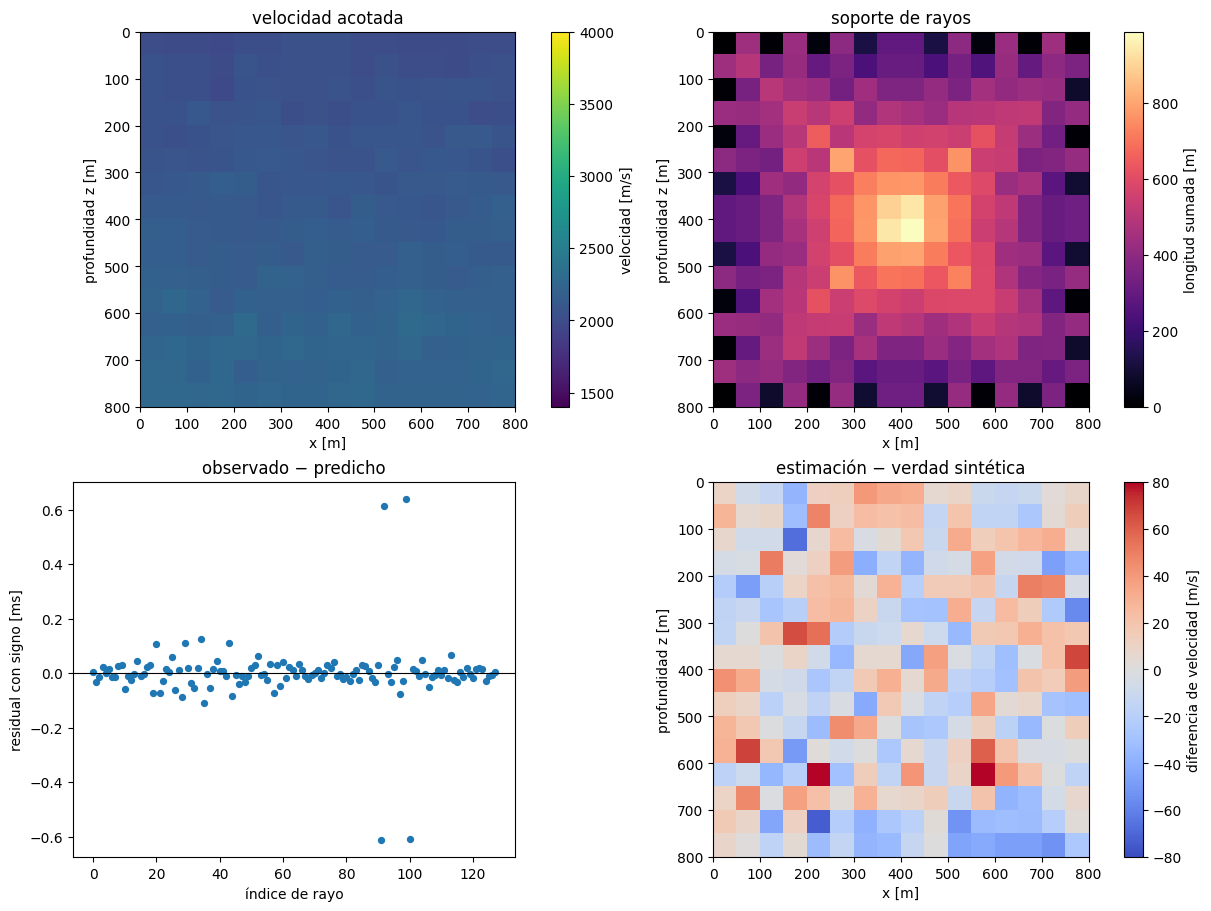

In [6]:
# Grafique estimación, cobertura, residuales y error solo sintético.
truth_error = velocity - truth
limit = max(float(np.max(np.abs(truth_error))), 1e-12)
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
image = axes[0, 0].imshow(velocity, origin="upper", extent=(0, 800, 800, 0),
                          cmap="viridis", vmin=1400, vmax=4000)
axes[0, 0].set(title="velocidad acotada", xlabel="x [m]",
               ylabel="profundidad z [m]")
fig.colorbar(image, ax=axes[0, 0], label="velocidad [m/s]")
image = axes[0, 1].imshow(coverage, origin="upper", extent=(0, 800, 800, 0),
                          cmap="magma")
axes[0, 1].set(title="soporte de rayos", xlabel="x [m]",
               ylabel="profundidad z [m]")
fig.colorbar(image, ax=axes[0, 1], label="longitud sumada [m]")
axes[1, 0].scatter(np.arange(len(residual_ms)), residual_ms, s=18)
axes[1, 0].axhline(0, color="black", linewidth=0.8)
axes[1, 0].set(title="observado − predicho", xlabel="índice de rayo",
               ylabel="residual con signo [ms]")
image = axes[1, 1].imshow(truth_error, origin="upper", extent=(0, 800, 800, 0),
                          cmap="coolwarm", vmin=-limit, vmax=limit)
axes[1, 1].set(title="estimación − verdad sintética",
               xlabel="x [m]", ylabel="profundidad z [m]")
fig.colorbar(image, ax=axes[1, 1], label="diferencia de velocidad [m/s]")
plt.show()

El panel de velocidad es una estimación paramétrica dentro de las cotas declaradas. El panel de cobertura suma longitud de trayectoria y no es incertidumbre. El panel de residual usa tiempo observado menos predicho en el orden de los rayos. El panel de error respecto de verdad existe solo porque este notebook generó un modelo sintético conocido; no debe copiarse a un levantamiento de usuario sin etiquetas ni describirse como validación geológica.

## Comparación

Hay dos comparaciones con preguntas distintas. Primero, el solver de conjunto activo del producto y la rutina publicada de mínimos cuadrados acotados de SciPy resuelven la misma cuadrática definida positiva con observaciones, pesos, regularización y cotas físicas idénticos. Al factorizar la Hessiana, la cuadrática se expresa como un sistema de mínimos cuadrados. El método trust-region reflective de SciPy es una implementación independiente del optimizador. La concordancia comprueba el resultado de optimización; ambos métodos comparten la matriz de rayos y el objetivo, por lo que no constituye un oráculo geofísico directo independiente.

Segundo, LSQR de SciPy resuelve el mismo término de datos ponderado y las mismas penalizaciones de regularización sin cotas de velocidad. LSQR es un algoritmo iterativo de mínimos cuadrados basado en la bidiagonalización de Golub–Kahan. Su sistema aumentado contiene exactamente la energía de diferencias del grafo y el ridge; solo se quita la caja. Así se aísla el efecto de la restricción física de las definiciones de datos y regularización.

Para hacer visible el contraste, la entrada de estrés agrega una rampa determinista desde −0.1 hasta +0.1 segundos a los mismos 128 tiempos sintéticos. Es un control matemático intencionalmente extremo, no un modelo realista de ruido de campo. El solver del producto y la solución acotada de SciPy permanecen entre 1400 y 4000 m/s. Los parámetros LSQR sin restricciones se grafican en el espacio q; se cuentan directamente los parámetros fuera de caja o con lentitud no positiva. Nunca se convierte una lentitud inválida en una velocidad de apariencia plausible.

La concordancia entre conjunto activo y trust-region acotados comprueba dos implementaciones de un objetivo finito. Su diferencia respecto de LSQR sin restricciones muestra qué cambia al quitar la restricción paramétrica; no prueba que un solver sea siempre más preciso. Una comprobación física independiente requiere otra física directa y observaciones controladas independientemente.

La solicitud perturbada cambia solo el vector de tiempos y mantiene intacto el control original. Una rampa de 100 ms es deliberadamente mucho mayor que sigma declarado de 1 ms; así se examina el comportamiento numérico en cotas activas. Es un caso de estrés, no otro escenario geológico ni un modelo de ruido de campo.

In [7]:
# Cambie solo los tiempos para crear otra entrada de estrés de cotas.
stress = dict(request)
stress["id"] = "m12-active-bound-stress-control"
stress["times_s"] = (observed + np.linspace(-0.1, 0.1, len(observed))).tolist()
stress_bytes = json.dumps(stress, allow_nan=False).encode("utf-8")
stress_result = user_velocity.calculate(stress_bytes)
stress_record = stress_result["results"]["classical"]
stress_velocity = np.asarray(stress_record["velocity_m_s"])
print("rampa de estrés: ±0.1 s; no es ruido de campo")
print("celdas activas:", stress_record["active_bound_cells"],
      "iteraciones:", stress_record["solver_iterations"])
print("WRMS de estrés:", round(stress_record["data_wrms"], 3),
      "KKT proyectado:", f"{stress_record['kkt_relative']:.3e}")

rampa de estrés: ±0.1 s; no es ruido de campo
celdas activas: 127 iteraciones: 134
WRMS de estrés: 17.43 KKT proyectado: 2.632e-16


El solver acotado de SciPy se ejecuta sobre la misma Hessiana cuadrática y término lineal. La factorización hace que su objetivo de mínimos cuadrados acotados sea equivalente salvo una constante aditiva. La concordancia compara optimizadores numéricos; la matriz de rayos, la referencia y los datos siguen siendo compartidos.

In [8]:
# Construya la misma cuadrática y resuelva mínimos cuadrados con caja.
reference_slowness = 1.0 / truth.ravel()
weights = ray_lengths / (1000 * sigma[:, None])
target = (np.asarray(stress["times_s"])
          - ray_lengths @ reference_slowness) / sigma
gram = _difference_gram()
hessian = weights.T @ weights + 100 * gram + 0.01 * np.eye(256)
rhs = weights.T @ target
lower = 1000 * (1 / 4000 - reference_slowness)
upper = 1000 * (1 / 1400 - reference_slowness)
factor = np.linalg.cholesky(hessian).T
reference_target = np.linalg.solve(factor.T, rhs)
scipy_bounded = lsq_linear(
    factor, reference_target, bounds=(lower, upper),
    method="trf", tol=1e-13, lsq_solver="exact", max_iter=2000,
)
bounded_velocity = (
    1 / (reference_slowness + scipy_bounded.x / 1000)
).reshape(16, 16)
bounded_difference = float(np.max(np.abs(stress_velocity - bounded_velocity)))
print("éxito SciPy acotado:", scipy_bounded.success)
print("diferencia máxima de velocidad [m/s]:", f"{bounded_difference:.3e}")

éxito SciPy acotado: True
diferencia máxima de velocidad [m/s]: 3.683e-11


La llamada LSQR usa los mismos datos ponderados y matrices de penalización, pero omite la caja de parámetros. El factor raíz de la matriz Gram de diferencias del producto conserva su energía cuadrática. Los resultados LSQR permanecen en el espacio q, porque una lentitud negativa no es una velocidad válida.

In [9]:
# Resuelva el mismo objetivo aumentado con LSQR de SciPy, sin cotas.
eigenvalues, eigenvectors = np.linalg.eigh(gram)
positive = eigenvalues > 1e-10
difference_root = (
    np.sqrt(eigenvalues[positive])[:, None] * eigenvectors[:, positive].T
)
augmented = np.vstack((
    weights, np.sqrt(100) * difference_root, np.sqrt(0.01) * np.eye(256),
))
augmented_rhs = np.concatenate((
    target, np.zeros(difference_root.shape[0] + 256),
))
unbounded = lsqr(
    augmented, augmented_rhs, atol=1e-12, btol=1e-12, iter_lim=2048,
)
lsqr_q = unbounded[0]
lsqr_slowness = reference_slowness + lsqr_q / 1000
outside = (lsqr_q < lower) | (lsqr_q > upper)
nonpositive = lsqr_slowness <= 0
print("detención / iteraciones LSQR:", unbounded[1], unbounded[2])
print("parámetros fuera de caja:", int(outside.sum()), "de", len(outside))
print("lentitud no positiva:", int(nonpositive.sum()), "de", len(nonpositive))

detención / iteraciones LSQR: 2 253
parámetros fuera de caja: 52 de 256
lentitud no positiva: 8 de 256


### Estimaciones acotadas y sin restricciones

El primer panel muestra el resultado acotado del producto; los demás mantienen LSQR en el espacio de parámetros y marcan la diferencia directamente.

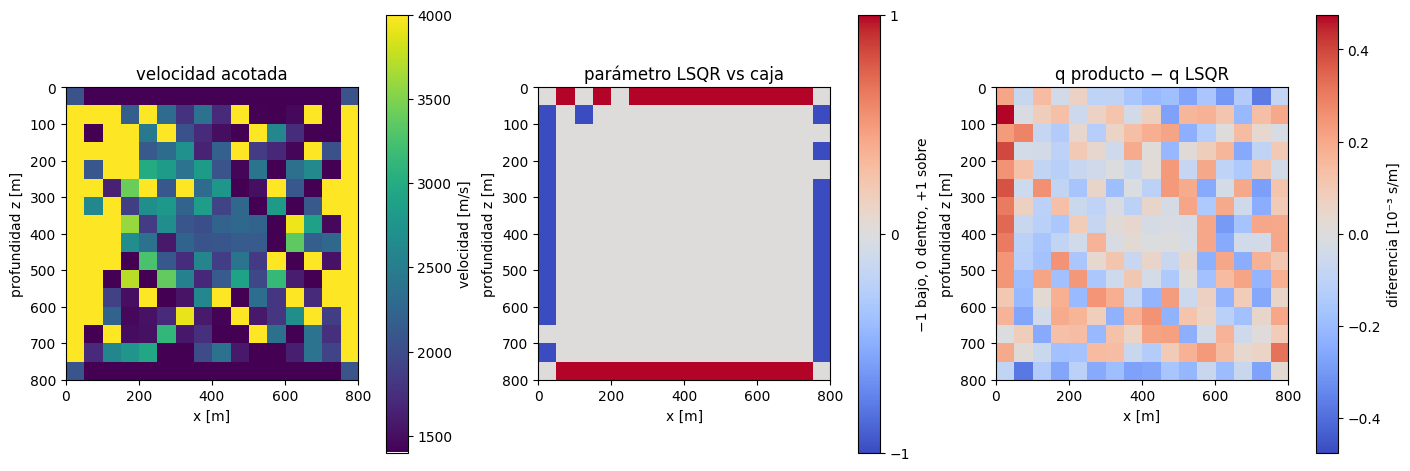

In [10]:
# Compare velocidad acotada con parámetros LSQR en el espacio q.
box_state = np.zeros(256, dtype=int)
box_state[lsqr_q < lower] = -1
box_state[lsqr_q > upper] = 1
box_state = box_state.reshape(16, 16)
product_q = 1000 * (1 / stress_velocity.ravel() - reference_slowness)
difference = (product_q - lsqr_q).reshape(16, 16)
limit = max(float(np.max(np.abs(difference))), 1e-12)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), constrained_layout=True)
image = axes[0].imshow(stress_velocity, origin="upper", extent=(0, 800, 800, 0),
                       cmap="viridis", vmin=1400, vmax=4000)
axes[0].set(title="velocidad acotada", xlabel="x [m]",
            ylabel="profundidad z [m]")
fig.colorbar(image, ax=axes[0], label="velocidad [m/s]")
image = axes[1].imshow(box_state, origin="upper", extent=(0, 800, 800, 0),
                       cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set(title="parámetro LSQR vs caja", xlabel="x [m]",
            ylabel="profundidad z [m]")
fig.colorbar(image, ax=axes[1], ticks=[-1, 0, 1],
             label="−1 bajo, 0 dentro, +1 sobre")
image = axes[2].imshow(difference, origin="upper", extent=(0, 800, 800, 0),
                       cmap="coolwarm", vmin=-limit, vmax=limit)
axes[2].set(title="q producto − q LSQR", xlabel="x [m]",
            ylabel="profundidad z [m]")
fig.colorbar(image, ax=axes[2], label="diferencia [10⁻³ s/m]")
plt.show()

La estimación del producto permanece entre 1400 y 4000 m/s. El panel LSQR muestra q en 10⁻³ s/m, no velocidad; el mapa categórico marca parámetros por debajo, dentro o por encima de la caja. El tercer panel muestra q del producto menos q de LSQR. La salida impresa cuenta las lentitudes no positivas y nunca las invierte para producir un mapa de apariencia plausible.

### Sensibilidad a la regularización

Lambda equilibra el término de datos escalado por incertidumbre con la energía de diferencias espaciales. El barrido cambia solo lambda y vuelve a ejecutar el método del producto para cada valor. Informa WRMS de datos ponderado y energía de diferencias del grafo calculada desde cada modelo devuelto. Estas cantidades tienen unidades y roles distintos, por eso aparecen en ejes separados en vez de convertirse en una puntuación combinada inventada.

Un WRMS de datos menor significa un ajuste ponderado más cercano a los tiempos entregados. Una energía de diferencias menor significa una perturbación más suave bajo el operador de esta grilla. Ninguna identifica por sí sola un modelo físicamente correcto. No seleccione lambda minimizando el error frente a la verdad sintética: eso filtra la respuesta a la selección del modelo. Un estudio de campo requiere un protocolo definido de antemano, como una partición independiente de validación o un modelo de ruido justificado. Cambiar sigma modifica los pesos relativos de observación; no cambia la geometría de rayos ni la física de propagación.

Las dos celdas siguientes cambian un único peso físico de regularización cada vez. Sus salidas forman puntos de una trayectoria medida; no se elige automáticamente usando el error respecto de verdad.

In [11]:
# Cambie lambda a uno y vuelva a ejecutar el cálculo del producto.
low_request = dict(request)
low_request["lambda"] = 1.0
low_record = user_velocity.calculate(
    json.dumps(low_request, allow_nan=False).encode("utf-8")
)["results"]["classical"]
low_q = 1000 * (1 / np.asarray(low_record["velocity_m_s"]).ravel()
                - 1 / truth.ravel())
low_wrms = float(low_record["data_wrms"])
low_roughness = float(low_q @ gram @ low_q)
nominal_q = 1000 * (1 / velocity.ravel() - 1 / truth.ravel())
nominal_roughness = float(nominal_q @ gram @ nominal_q)
print("lambda=1, WRMS:", round(low_wrms, 5),
      "energía de diferencias:", f"{low_roughness:.6g}")

lambda=1, WRMS: 0.10964 energía de diferencias: 0.0280667


Esta segunda resolución cambia solo lambda a 10000; los rayos, picks, incertidumbres, referencia y operador quedan fijos. El valor alto deliberado expone el régimen de mayor suavizado. Compare el ajuste ponderado y la rugosidad con lambda 1 y el valor nominal 100. Es un ajuste experimental, no un prior calibrado en campo.

In [12]:
# Cambie solo lambda y vuelva a ejecutar el mismo método del producto.
high_request = dict(request)
high_request["lambda"] = 10000.0
high_record = user_velocity.calculate(
    json.dumps(high_request, allow_nan=False).encode("utf-8")
)["results"]["classical"]
high_q = 1000 * (1 / np.asarray(high_record["velocity_m_s"]).ravel()
                 - 1 / truth.ravel())
high_wrms = float(high_record["data_wrms"])
high_roughness = float(high_q @ gram @ high_q)
print("lambda=10000, WRMS:", round(high_wrms, 5),
      "energía de diferencias:", f"{high_roughness:.6g}")

lambda=10000, WRMS: 0.5908 energía de diferencias: 0.00254604


### Trayectoria de regularización para las mismas llegadas

Esta vista muestra ajuste y rugosidad en ejes separados en lugar de ocultar su compromiso en una sola puntuación.

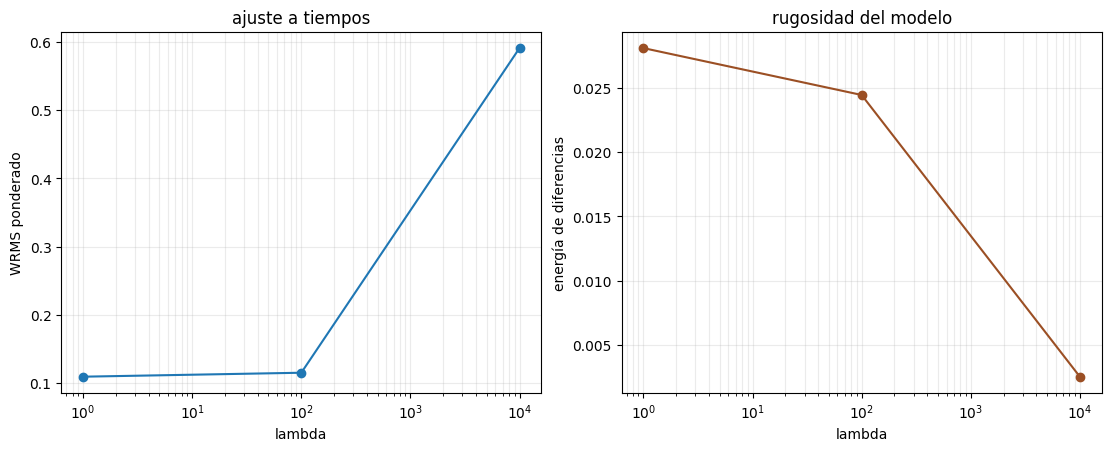

In [13]:
# Grafique ajuste y suavidad como respuestas separadas a regularización.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), constrained_layout=True)
axes[0].semilogx([1, 100, 10000], [low_wrms, classical["data_wrms"], high_wrms],
                 marker="o")
axes[0].set(xlabel="lambda", ylabel="WRMS ponderado", title="ajuste a tiempos")
axes[0].grid(True, which="both", alpha=0.25)
axes[1].semilogx([1, 100, 10000],
               [low_roughness, nominal_roughness, high_roughness],
               marker="o", color="#9b4f24")
axes[1].set(xlabel="lambda", ylabel="energía de diferencias",
            title="rugosidad del modelo")
axes[1].grid(True, which="both", alpha=0.25)
plt.show()

Los tres puntos corresponden a lambda 1, 100 y 10000. Un WRMS menor indica ajuste ponderado más cercano a estos tiempos; una energía de diferencias menor indica un modelo más suave bajo esta discretización. Ninguna cantidad establece corrección física. Escoger lambda por el mínimo error sintético filtraría la respuesta y se evita deliberadamente.

### Usa el método con tus propios datos

La solicitud contiene schema, id, source, frame, units, ray_ids, rays_m, times_s, sigma_s y lambda. Cada fila rays_m es [x_fuente, z_fuente, x_receptor, z_receptor] en metros. El marco es local-x-z-down. Los tiempos y sus desviaciones estándar declaradas son segundos. Los identificadores conservan la identidad de fila; source registra la cita o permiso del titular y el alcance de derechos. Esta versión acepta entre 8 y 2048 rayos dentro de su dominio de coordenadas de 800 m por 800 m.

Para un levantamiento real, use picks de primeras llegadas documentados y la geometría en este marco exacto. Conserve los bytes originales y su hash fuera del notebook. No adivine un CRS desconocido, no invente incertidumbres ni cambie la etiqueta de derechos de datos del proveedor. Si los derechos no permiten el uso local, deténgase antes de leer el archivo. El modelo directo supone que cada segmento fuente–receptor es fijo y recto, no incorpora una corrección de tiempo de origen y usa el lambda recibido. No es refracción de rayos curvos, anisotropía, imágenes de formas de onda ni FWI.

La siguiente celda lee my-arrivals.json si existe un archivo permitido en la carpeta de trabajo del notebook. De lo contrario, repite el control sintético especificado para que un checkout limpio siga siendo reproducible. Para usar un levantamiento, revise el JSON contra el contrato, colóquelo en esa ruta y vuelva a ejecutar la celda. El mismo validador y solver del producto operan sobre los bytes originales. El resultado local no recibe puntuación de verdad. La CLI escribe una generación nueva sin sobrescribir otra existente; la entrada original permanece separada.

La ruta de ejemplo es local. Si no hay archivo, la solicitud creada de forma determinista mantiene reproducible una ejecución limpia. Si existe un levantamiento permitido, el mismo validador de contrato y solver del producto consumen esos bytes exactos; la salida permanece local y no se adjunta una puntuación de verdad a datos de usuario.

In [14]:
# Ejecute el flujo del producto sobre bytes locales permitidos si existen.
user_path = Path("my-arrivals.json")
if user_path.is_file():
    user_bytes = user_path.read_bytes()
    input_kind = "archivo local de usuario"
else:
    user_bytes = request_bytes
    input_kind = "control sintético creado"
user_request = user_velocity.validate_request(user_bytes)
user_result = user_velocity.calculate(user_bytes)
user_record = user_result["results"]["classical"]
print("entrada:", input_kind, "rayos:", len(user_request["ray_ids"]))
print("WRMS de datos:", round(user_record["data_wrms"], 5),
      "KKT proyectado:", f"{user_record['kkt_relative']:.3e}")
print("verdad: no se calcula una puntuación en este flujo")

entrada: control sintético creado rayos: 128
WRMS de datos: 0.11543 KKT proyectado: 1.328e-14
verdad: no se calcula una puntuación en este flujo


## Resultados

**Respuesta:** En el control determinista de 128 rayos, el producto informa WRMS ponderado de datos 0.115 y residuo KKT relativo proyectado menor que 1.4 × 10⁻¹⁴. Es el resultado del optimizador para una cuadrática de rayos fijos, no un modelo terrestre validado.

El modelo, la cobertura geométrica, los residuales con signo y el error respecto de la verdad sintética se muestran por separado porque responden preguntas distintas. La comparación de estrés muestra si concuerda un segundo optimizador acotado y cuántos parámetros LSQR sin restricciones salen de la caja física. El notebook calcula estos valores desde la tubería actual; no lee un resultado horneado. Solo el control sintético creado permite calcular error respecto de verdad. Un archivo de usuario recibe diagnósticos de ajuste y geometría, pero no precisión geológica inventada.

La perturbación de estrés es deliberadamente severa y no se interpreta como ruido de campo. El caso principal mantiene el control declarado de 1 ms. Un residual de datos bajo no demuestra que se haya recuperado la Tierra; el residual mide ajuste a picks y KKT mide optimalidad del objetivo discreto.

## Resumen

El flujo comienza con geometría e incertidumbre declaradas, construye un objetivo de lentitud ponderado alrededor de una referencia, impone el intervalo físico de velocidad durante la optimización y vuelve a calcular KKT proyectado desde el modelo devuelto. Un solver acotado de SciPy comprueba el optimizador de forma independiente; LSQR sin restricciones muestra las consecuencias de quitar la caja.

Las limitaciones físicas siguen siendo sustanciales. Los rayos rectos no se curvan cuando cambia el modelo. La formulación no tiene corrección de tiempo de origen, refracción, anisotropía, campo de ondas elásticas ni modelo de error de campo calibrado independientemente. Un mapa de celdas es la parametrización numérica, no resolución geológica demostrada. Use este cálculo local solo con entradas autorizadas cuyos unidades, marco, geometría e incertidumbres se conozcan, y mantenga separadas las evidencias sintéticas y de campo.

## Referencias

- [API lsq_linear de SciPy 1.15.2](https://docs.scipy.org/doc/scipy-1.15.2/reference/generated/scipy.optimize.lsq_linear.html) — optimizador acotado usado en la comprobación cruzada.
- [API LSQR de SciPy 1.15.2](https://docs.scipy.org/doc/scipy-1.15.2/reference/generated/scipy.sparse.linalg.lsqr.html) — solver iterativo sin restricciones de la comparación.
- [Paige y Saunders, LSQR: An Algorithm for Sparse Linear Equations and Sparse Least Squares](https://doi.org/10.1145/355984.355989) — base algorítmica de LSQR.
- [Ejemplo de primeras llegadas de Königsee en pyGIMLi](https://www.pygimli.org/_examples_auto/2_seismics/plot_04_koenigsee/) — flujo de refracción de campo separado, enlazado al proveedor; no son estos datos sintéticos.
- [Guía de inversión de pyGIMLi](https://www.pygimli.org/user-guide/inversion/) — contexto general del solver de campo separado.